# 05 · Final pipeline and the validation/leaderboard gap

Final model: RT-DETR-l at 1536 px trained on all 63 labelled clips. This notebook compares inference strategies, ensembles and shows why fold-0 validation and the public leaderboard disagree for some of them.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve() / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from hw2 import CLASSES
from hw2.analysis import load_run, metrics_table, curve, error_breakdown, worst_frames, draw
from hw2.data import find_data_root, fold_frames, load_all, make_folds, subsample

sns.set_theme(style="whitegrid", context="notebook")
IMG = Path("../images"); IMG.mkdir(exist_ok=True)
frames, boxes = load_all(find_data_root())


## All experiments, one table

In [2]:
exp = pd.read_csv('../results/experiments.csv')
exp = exp[exp.run.str.match(r'^(frcnn|retina|yolo|rtdetr)')]
exp[['run', 'mAP', 'AP50', 'AP_small', 'fps', 'train_min']].sort_values('mAP', ascending=False).round(4).reset_index(drop=True)

,run,mAP,AP50,AP_small,fps,train_min
0,rtdetr_all_lr,0.5394,0.8667,0.2919,10.06,177.7
1,rtdetr_all_1536,0.5385,0.8695,0.2865,10.40,172.7
2,rtdetr_s5_1536,0.3096,0.5510,0.1024,10.24,147.1
3,rtdetr_cost,0.3004,0.5436,0.1059,12.05,97.7
4,rtdetr_q500,0.2973,0.5414,0.0970,12.21,111.7
5,rtdetr_base,0.2971,0.5424,0.1085,10.04,105.9
6,rtdetr_lr,0.2961,0.5282,0.0963,9.87,139.1
7,rtdetr_s5,0.2945,0.5291,0.0973,12.57,108.4
8,rtdetr_s4_1536,0.2911,0.5180,0.0884,9.98,311.1
9,rtdetr_s4_1344,0.2808,0.5073,0.0804,12.31,240.4


## Inference strategies (RT-DETR-l 1536, fold 0)

Tiles are SAHI-style n×n overlapping crops merged with the full-frame pass by class-wise NMS. TTA is a horizontal flip merged the same way (Ultralytics' own `augment=True` does nothing for RT-DETR).

In [3]:
pd.read_csv('../results/inference_strategies.csv')

,tag,mAP,AP50,AP_small,AP_medium,AP_large,AR500,s/frame
0,full,0.3095,0.5511,0.1022,0.2331,0.4914,0.4728,0.1260
1,tta,0.3180,0.5736,0.1037,0.2444,0.4977,0.4834,0.2264
2,t2,0.2865,0.5398,0.0895,0.2146,0.4695,0.4831,0.2902
3,t2tta,0.2956,0.5511,0.0921,0.2241,0.4784,0.4920,0.3911
4,t3,0.2712,0.5097,0.0833,0.1971,0.4520,0.4712,0.3886


## Ensembles by weighted box fusion

In [4]:
pd.read_csv('../results/ensembles.csv')

,ensemble,weights,iou_thr,mAP,AP50,AP_small,AR500
0,rtdetr_s5_1536 (single model),NaN,NaN,0.3096,0.5510,0.1024,0.4729
1,4x RT-DETR,1:1:1:1,0.55,0.3006,0.5540,0.0841,0.4983
2,4x RT-DETR,1:1:1:1,0.65,0.3108,0.5673,0.0904,0.5088
3,RT-DETR 1536 + Faster R-CNN,2:1,0.60,0.3082,0.5651,0.0921,0.5066
4,RT-DETR 1536 + Faster R-CNN,2:1,0.70,0.3164,0.5746,0.0962,0.5153
5,RT-DETR 1536 + Faster R-CNN,3:1,0.60,0.3040,0.5566,0.0889,0.5067
6,RT-DETR 1536 + Faster R-CNN,3:1,0.70,0.3129,0.5682,0.0942,0.5155
7,RT-DETR 1536 TTA + Faster R-CNN,2:1,0.70,0.3322,0.6012,0.1032,0.5194
8,RT-DETR 1536 TTA + Faster R-CNN,2:1,0.80,0.3304,0.5952,0.1028,0.5263
9,RT-DETR 1536 TTA + Faster R-CNN,3:1,0.80,0.3301,0.5951,0.1041,0.5265


## Fold-0 validation vs public leaderboard

In [5]:
lb = pd.read_csv('../results/leaderboard.csv'); lb

,submission,description,fold0_mAP,public_LB
0,frcnn_base,Faster R-CNN R50-FPN v2 baseline,0.2595,0.2125
1,rtdetr_base,RT-DETR-l 1344,0.2971,0.3137
2,rtdetr_1536,RT-DETR-l 1536,0.3096,0.3426
3,rtdetr_all_1536,RT-DETR-l 1536 trained on all 63 clips,NaN,0.3465
4,rtdetr_all_1536+TTA,same + horizontal-flip TTA,0.3180,0.3458
5,ensemble,RT-DETR(all)+TTA and Faster R-CNN (16-256 anch...,0.3322,0.3251


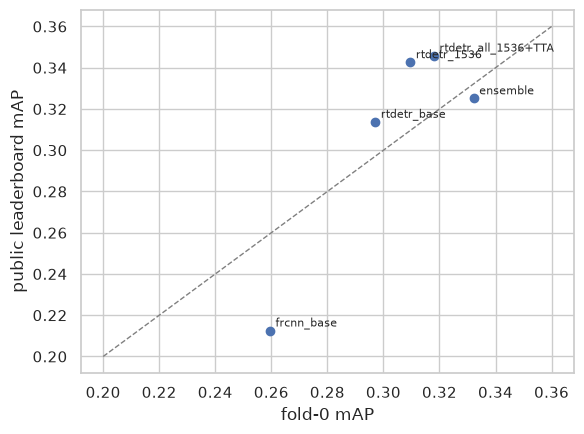

In [6]:
d = lb.dropna(subset=['fold0_mAP'])
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot([0.2, 0.36], [0.2, 0.36], '--', c='grey', lw=1)
ax.scatter(d.fold0_mAP, d.public_LB)
for _, r in d.iterrows(): ax.annotate(r.submission, (r.fold0_mAP, r.public_LB), fontsize=8, xytext=(4, 3), textcoords='offset points')
ax.set_xlabel('fold-0 mAP'); ax.set_ylabel('public leaderboard mAP'); fig.tight_layout(); fig.savefig(IMG / 'val_vs_lb.png', dpi=140)

## Why: the test set contains low-resolution clips that the labelled data does not have

,train (folds 1-4),validation (fold 0),test
width,,,
<800,0.000,0.000,0.084
800-1100,0.000,0.000,0.073
1100-1500,0.320,0.093,0.502
1500-2500,0.495,0.622,0.340
>2500,0.185,0.285,0.000


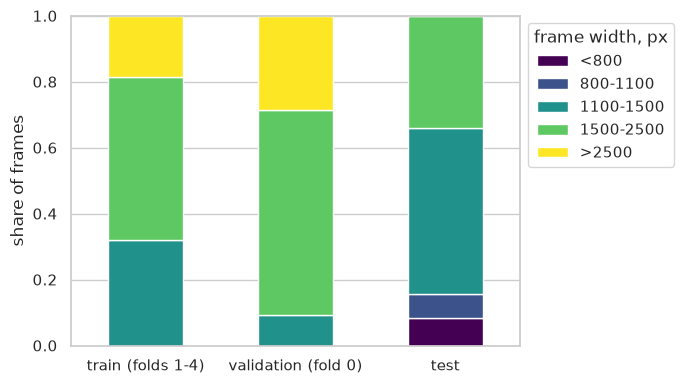

In [7]:
from hw2.data import load_test
t = load_test()
bins = [0, 800, 1100, 1500, 2500, 5000]; labels = ['<800', '800-1100', '1100-1500', '1500-2500', '>2500']
f = make_folds(frames); fr = frames.merge(f[['clip', 'fold']], on='clip')
def share(df): return pd.cut(df.width, bins, labels=labels).value_counts(normalize=True).reindex(labels).fillna(0)
res = pd.DataFrame({'train (folds 1-4)': share(fr[fr.fold != 0]), 'validation (fold 0)': share(fr[fr.fold == 0]), 'test': share(t)})
ax = res.T.plot.bar(stacked=True, figsize=(7, 4), colormap='viridis'); ax.set_ylabel('share of frames'); ax.set_xlabel(''); plt.xticks(rotation=0)
plt.legend(title='frame width, px', bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.savefig(IMG / 'resolution_shift.png', dpi=140); res.round(3)

## Low-resolution augmentation

Training with random down/up-sampling (30% of images, width 640-1000 px) and testing on fold 0 degraded the same way:

In [8]:
pd.read_csv('../results/lowres_augmentation.csv')

,"model, input",mAP,AP50,AP_small,AR500
0,"base, clean",0.3096,0.5510,0.1024,0.4729
1,"base, degraded 800px",0.2776,0.4887,0.0713,0.4369
2,"lowres-aug, clean",0.2961,0.5282,0.0965,0.4644
3,"lowres-aug, degraded 800px",0.2784,0.4943,0.0814,0.4456
